In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
 
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder, RobustScaler
from sklearn.metrics import classification_report, confusion_matrix
 
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
 
import warnings
warnings.filterwarnings('ignore')

In [2]:
df = pd.read_csv('healthcare-dataset-stroke-data.csv')
df

,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1
...,...,...,...,...,...,...,...,...,...,...,...,...
5105,18234,Female,80.0,1,0,Yes,Private,Urban,83.75,NaN,never smoked,0
5106,44873,Female,81.0,0,0,Yes,Self-employed,Urban,125.20,40.0,never smoked,0
5107,19723,Female,35.0,0,0,Yes,Self-employed,Rural,82.99,30.6,never smoked,0
5108,37544,Male,51.0,0,0,Yes,Private,Rural,166.29,25.6,formerly smoked,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [4]:
df.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
for cols in df.select_dtypes(include='object').columns:
    print(f'{cols} : {df[cols].unique()}'   )

gender : ['Male' 'Female' 'Other']
ever_married : ['Yes' 'No']
work_type : ['Private' 'Self-employed' 'Govt_job' 'children' 'Never_worked']
Residence_type : ['Urban' 'Rural']
smoking_status : ['formerly smoked' 'never smoked' 'smokes' 'Unknown']


- The data is almost clean and the column bmi have null values for cleaning

#### Data Cleaning

In [7]:
df['bmi']

0       36.6
1        NaN
2       32.5
3       34.4
4       24.0
        ... 
5105     NaN
5106    40.0
5107    30.6
5108    25.6
5109    26.2
Name: bmi, Length: 5110, dtype: float64

Text(0.5, 0, 'BMI')

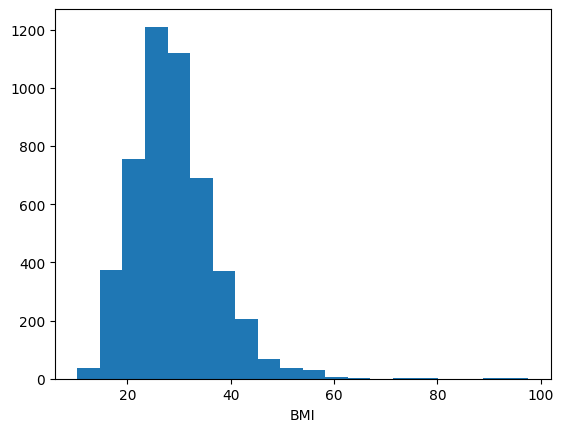

In [8]:
# check bmi column data distribution

plt.hist(df['bmi'], bins=20)
plt.xlabel('BMI')   

In [9]:
df['bmi'].fillna(df['bmi'].mean(), inplace=True)

Text(0.5, 1.0, 'Transformed BMI Distribution')

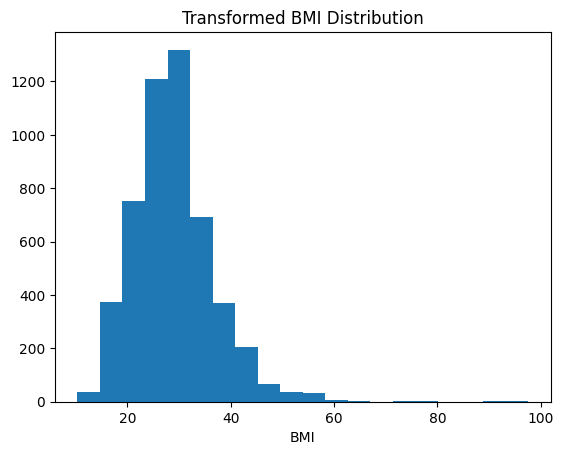

In [10]:
plt.hist(df['bmi'], bins=20)
plt.xlabel('BMI') 
plt.title('Transformed BMI Distribution') 

#### Data Transformation

In [11]:
x = df.drop('stroke', axis=1)
y = df['stroke']

y.value_counts()

stroke
0    4861
1     249
Name: count, dtype: int64

In [12]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42, stratify = y)

In [13]:
train_df = x_train.copy()
train_df['stroke'] = y_train.values

Text(0.5, 1.0, 'Feature Distribution (train set)')

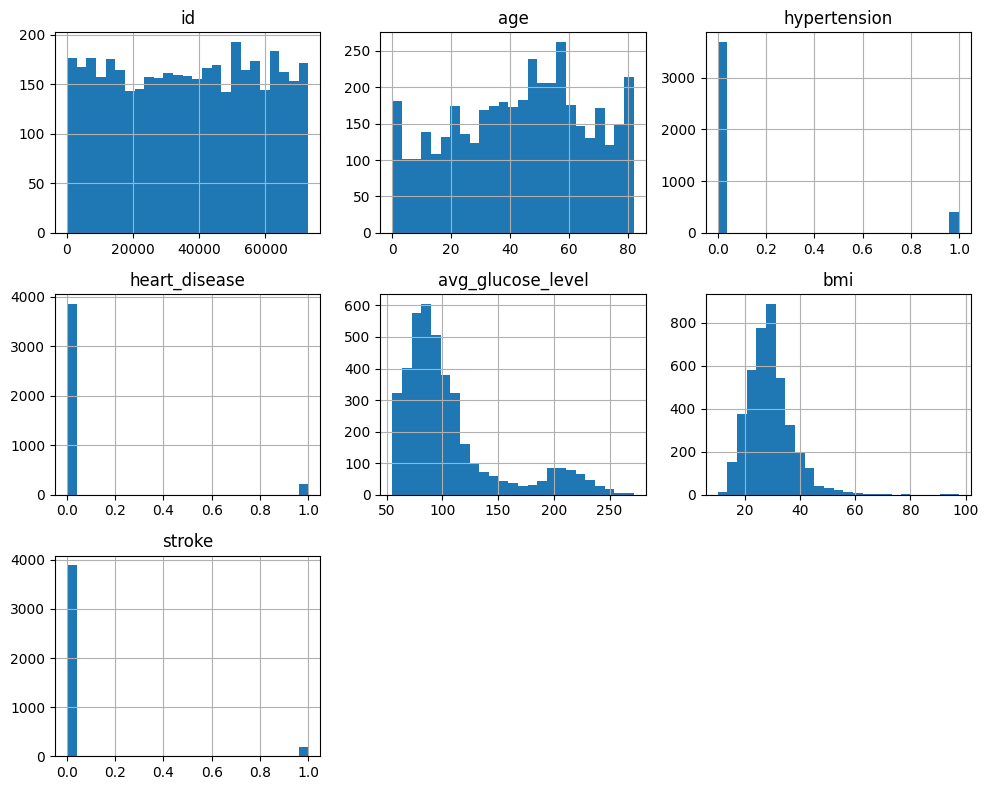

In [14]:
train_df.hist(bins = 25, figsize = (10,8))
plt.tight_layout()
plt.title('Feature Distribution (train set)')

Text(0.5, 1.0, 'Correlation Heatmap (train set)')

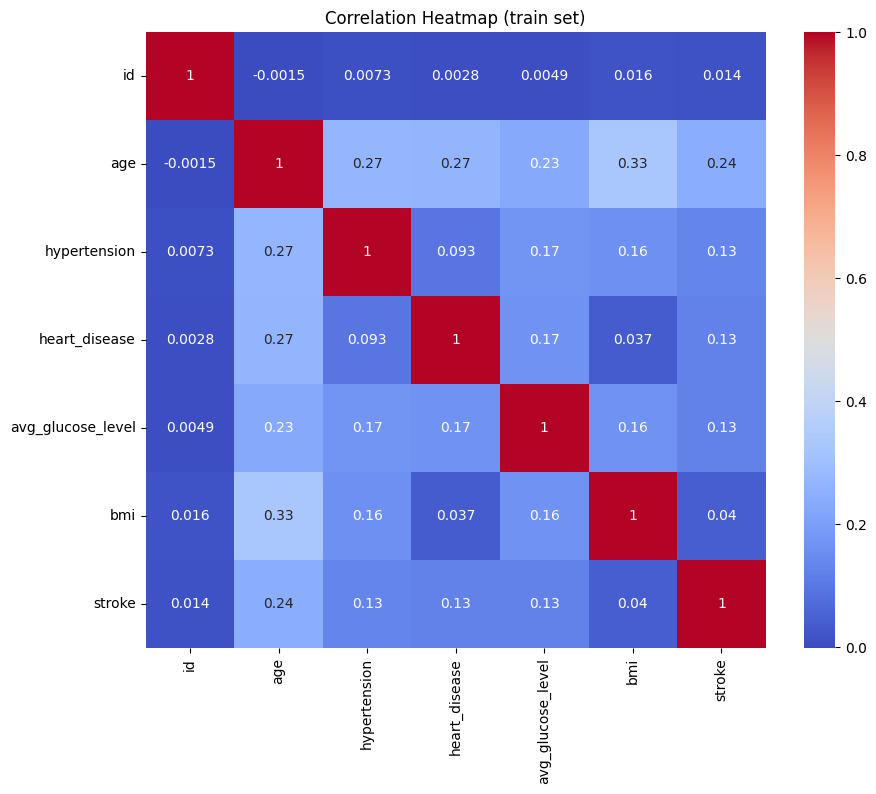

In [18]:
df_num = train_df.select_dtypes(exclude = 'object')
plt.figure(figsize = (10,8))
sns.heatmap(df_num.corr(), annot = True, cmap = 'coolwarm')
plt.title('Correlation Heatmap (train set)')

Text(0.5, 1.0, 'Boxplot of Numerical Features (train set)')

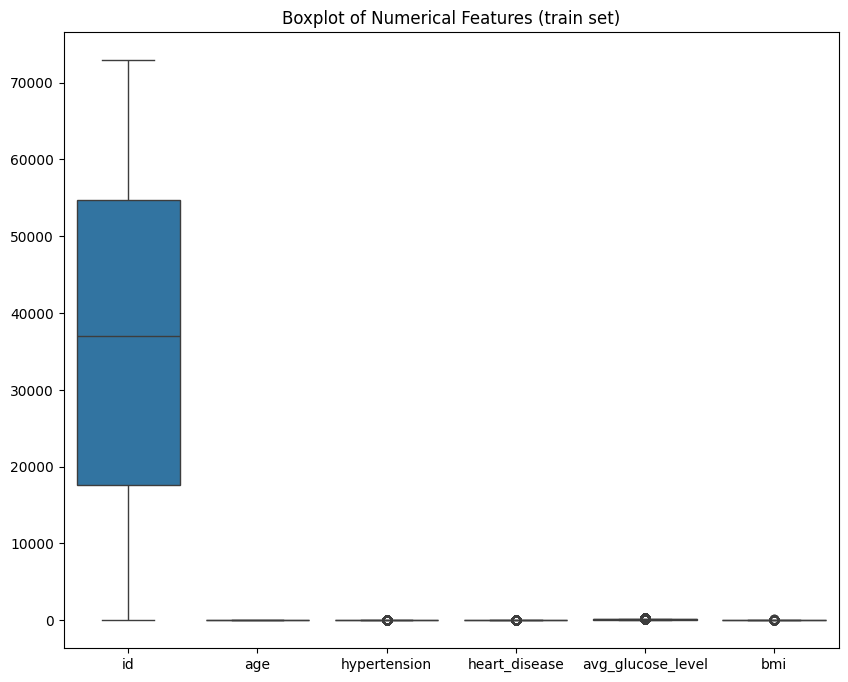

In [21]:
plt.figure(figsize = (10,8))
sns.boxplot(data=x_train.select_dtypes(include=['float64', 'int64']))
plt.title('Boxplot of Numerical Features (train set)')

In [22]:
cat_cols = x_train.select_dtypes(include='object').columns.tolist()
num_cols = x_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

In [23]:
encoder = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1)
x_train[cat_cols] = encoder.fit_transform(x_train[cat_cols])
x_test[cat_cols]  = encoder.transform(x_test[cat_cols])

In [24]:
scaler = RobustScaler()
x_train = scaler.fit_transform(x_train)
x_test = scaler.transform(x_test)

In [25]:
# Class Imbalance Check
neg = (y_train == 0).sum()
pos = (y_train == 1).sum()
spw = neg / pos   # scale_pos_weight for XGBoost
print(f"\nClass balance — 0: {neg} | 1: {pos} | scale_pos_weight: {spw:.2f}")


Class balance — 0: 3889 | 1: 199 | scale_pos_weight: 19.54


#### Data Modeling

In [26]:
lg = LogisticRegression(class_weight = 'balanced', random_state=42)
lg.fit(x_train, y_train)
y_pred_lg = lg.predict(x_test)
print('Logistic Regression\n')
print(classification_report(y_test, y_pred_lg))

Logistic Regression

              precision    recall  f1-score   support

           0       0.99      0.74      0.85       972
           1       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.54      1022
weighted avg       0.94      0.75      0.82      1022



In [27]:
xg = XGBClassifier(scale_pos_weight=spw, random_state=42)
xg.fit(x_train, y_train)
y_pred_xg = xg.predict(x_test)
print('XGBoost\n')
print(classification_report(y_test, y_pred_xg))

XGBoost

              precision    recall  f1-score   support

           0       0.96      0.97      0.96       972
           1       0.24      0.18      0.20        50

    accuracy                           0.93      1022
   macro avg       0.60      0.58      0.58      1022
weighted avg       0.92      0.93      0.93      1022

